[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/NadavFireman/Representation-Learning-Midterm-DAE-SimCLR/blob/main/colab_dae_grids.ipynb)

# Part A: tuning the DAE (A2)

The DAE's hyperparameters, chosen by **val k-NN top-1** (k = 20, cosine), never by reconstruction error, and never on the test set. Five grids, one after the other, as in the DL final project: each grid tries **every combination** of its hyperparameters, the others at the best so far, and its winner goes on to the next grid. It starts from the current DAE (`config.py`), and each number gets one value below it and two above.

- **Grid 1, the noise:** type (salt and pepper, mask, Gaussian, patch_mask as in MAE, block as in the context encoder) × level, and the patch size for patch_mask.
- **Grid 2, the architecture:** the channels of the two conv layers × the length of h.
- **Grid 3, regularization:** dropout on h × augmentation × batch size.
- **Grid 4, the optimizer** × the activation, before the learning rate: each optimizer has its own.
- **Grid 5, the learning rate** × weight decay × the scheduler.

**Stage 1** (the proxy): each DAE trains on a random, class-balanced 10% of the training images for 10 epochs, scored every 2 epochs with a 10,000-image k-NN bank. **Stage 2:** the 5 best of all the grids train on all the images for 20 epochs, with the full bank; the best is the choice, saved to `midterm_runs/tuning_choice.json` as `"dae"`. The last cell draws the A2 plot, reconstruction error against k-NN, over every trial.

Every combination gets a row: 60 + 64 + 45 + 20 + 24 = 213. On one L4 runtime, about 1.5 minutes a run: stage 1 about 4.5 hours (181 different runs), stage 2 about 1.5 hours. After a disconnect, run every cell again from the top: the finished runs are read from Drive, not trained again.

## Setup
Downloads the repository (or pulls the latest code), installs it and checks the GPU.

In [1]:
import os

REPO = "/content/Representation-Learning-Midterm-DAE-SimCLR"
if not os.path.exists(REPO):
    !git clone https://github.com/NadavFireman/Representation-Learning-Midterm-DAE-SimCLR.git {REPO}
os.chdir(REPO)
!git pull
!git log --oneline -1

Cloning into '/content/Representation-Learning-Midterm-DAE-SimCLR'...
remote: Enumerating objects: 149, done.
remote: Counting objects: 100% (149/149), done.
remote: Compressing objects: 100% (116/116), done.
remote: Total 149 (delta 98), reused 84 (delta 33), pack-reused 0 (from 0)
Receiving objects: 100% (149/149), 667.81 KiB | 786.00 KiB/s, done.
Resolving deltas: 100% (98/98), done.
Already up to date.
13323c5 (HEAD -> main, origin/main, origin/HEAD) DAE search: grid 6 (a second noise, combined augmentations) and grid 7 (smaller conv 2 and patch)


In [2]:
%pip install -q -r requirements.txt

import torch
assert torch.cuda.is_available(), "No GPU. Runtime → Change runtime type → L4 GPU, then rerun this cell."
print(torch.cuda.get_device_name(0), "|", os.cpu_count(), "CPU cores")

NVIDIA L4 | 12 CPU cores


## Drive
Every run writes to `midterm_runs`, next to the earlier runs. Stage 1 runs have `search_pretrain` in their folder name, stage 2 runs `tune_pretrain`.

In [3]:
from google.colab import drive

drive.mount("/content/drive")
DRIVE_DIR = "/content/drive/MyDrive/לימודים/תואר שני/שנה ב/סמסטר א/למידת ייצוגים במודלים עמוקים/מטלות/מטלת אמצע"
OUT = f"{DRIVE_DIR}/midterm_runs"
assert os.path.isdir(OUT), f"no folder {OUT}"

Mounted at /content/drive


## TensorBoard
Filter the runs with `search_pretrain` or `tune_pretrain`, then *Toggle all runs*. `epoch/val_knn_top1` and `epoch/val_loss` compare the trials, IMAGES shows the noisy inputs and the reconstructions, the TEXT tab each run's `run_info`.

In [4]:
%load_ext tensorboard
%tensorboard --logdir "{OUT}"

<IPython.core.display.Javascript object>

## The search
`grid_search_dae` trains one DAE for every combination of its grid (the rest at the best so far), keeps the best by val k-NN in `best`, and adds every trial to `results`. `train` runs train.py only if the run has no `results.json` yet, so combinations that are the same run (the patch size of a noise without patches) are trained once and read from Drive.

In [5]:
import importlib
import itertools
import json
import sys

import matplotlib.pyplot as plt
import pandas as pd

STAGE1 = "--mode pretrain --search --data_fraction 0.1"  # 10% of the images, 10 epochs, a 10,000-image k-NN bank
STAGE2 = "--mode pretrain --tune --num_epochs 20"  # all the images, the full bank, val only (no test)
CHOICE_FILE = f"{OUT}/tuning_choice.json"
# The current DAE (config.py); every grid starts from the best so far
best = {"noise_type": "salt_pepper", "noise_level": 0.5, "patch_size": 8, "conv1": 32, "conv2": 64,
        "latent_dim": 256, "dropout": 0.0, "augment": "flip", "batch_size": 512, "optimizer": "adamw",
        "activation": "gelu", "lr": 0.001, "wd": 0.01, "scheduler": "none"}
results = []  # every trial of stage 1


def flags_of(params):
    """The train.py flags of one DAE."""
    p = dict(params)
    return f"--channels {p.pop('conv1')} {p.pop('conv2')} " + " ".join(f"--{k} {v}" for k, v in p.items())


def folder_of(flags):
    """The run folder train.py uses for these flags (run_info.folder_name)."""
    import config, utils, run_info
    for module in (config, utils, run_info):
        importlib.reload(module)
    sys.argv = ["train.py", *flags.split(), "--output_dir", OUT]
    return f"{OUT}/{run_info.folder_name(utils.parse_args().mode)}"


def train(flags):
    """One run of train.py (skipped if it finished before): its val numbers and its folder."""
    if not os.path.exists(f"{folder_of(flags)}/results.json"):
        !python train.py {flags} --output_dir "{OUT}"
    folder = folder_of(flags)
    with open(f"{folder}/results.json") as f:
        return {**json.load(f), "run": os.path.basename(folder)}


def grid_search_dae(**grid):
    """Every combination of grid, the rest at the best so far; the best by val k-NN goes on."""
    rows = []
    for values in itertools.product(*grid.values()):
        params = {**best, **dict(zip(grid, values))}
        r = train(f"{STAGE1} {flags_of(params)}")
        rows.append({**params, "val_knn": r["val_knn_top1"], "val_loss": r["val_loss"], "run": r["run"]})
    results.extend(rows)
    top = max(rows, key=lambda row: row["val_knn"])
    best.update({k: top[k] for k in grid})  # the winner goes on to the next grid
    print("best so far:", best)
    table = pd.DataFrame(rows).sort_values("val_knn", ascending=False)
    display(table[[*grid, "val_knn", "val_loss"]].head(10).round(4))
    return table

## Grid 1, the noise
Its type × level × patch size: 5 × 4 × 3 = 60 combinations. The patch size changes only patch_mask, so for the other noises its 3 values are the same run, trained once: 28 runs.

In [6]:
results_1 = grid_search_dae(noise_type=["salt_pepper", "mask", "gaussian", "patch_mask", "block"],
                            noise_level=[0.4, 0.5, 0.6, 0.7], patch_size=[4, 8, 16])

best so far: {'noise_type': 'patch_mask', 'noise_level': 0.5, 'patch_size': 4, 'conv1': 32, 'conv2': 64, 'latent_dim': 256, 'dropout': 0.0, 'augment': 'flip', 'batch_size': 512, 'optimizer': 'adamw', 'activation': 'gelu', 'lr': 0.001, 'wd': 0.01, 'scheduler': 'none'}


,noise_type,noise_level,patch_size,val_knn,val_loss
39,patch_mask,0.5,4,0.0516,0.2808
36,patch_mask,0.4,4,0.0503,0.2612
47,patch_mask,0.7,16,0.0498,0.5335
34,gaussian,0.7,8,0.0496,0.2583
35,gaussian,0.7,16,0.0496,0.2583
33,gaussian,0.7,4,0.0496,0.2583
42,patch_mask,0.6,4,0.0491,0.3063
44,patch_mask,0.6,16,0.0491,0.4599
13,mask,0.4,8,0.0491,0.2726
14,mask,0.4,16,0.0491,0.2726


## Grid 2, the architecture
The channels of the two conv layers and the length of h: 4 × 4 × 4 = 64. Conv 1 with 24 channels and conv 2 with 128 is the one combination where conv 2's output (128 × 16 × 16) is larger than conv 1's (24 × 32 × 32).

In [7]:
results_2 = grid_search_dae(conv1=[24, 32, 48, 64], conv2=[48, 64, 96, 128], latent_dim=[128, 256, 384, 512])

Seed set to 42
Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
`Trainer(limit_train_batches=1.0)` was configured so 100% of the batches per epoch will be used..
`Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..
`Trainer(limit_test_batches=1.0)` was configured so 100% of the batches will be used..
DenoisingAutoEncoder(
  (encoder): Sequential(
    (0): Conv2d(3, 24, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): GELU(approximate='none')
    (2): Conv2d(24, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): GELU(approximate='none')
    (4): Flatten(start_dim=1, end_dim=-1)
    (5): Linear(in_features=32768, out_features=128, 

,conv1,conv2,latent_dim,val_knn,val_loss
34,48,48,384,0.0541,0.2739
47,48,128,512,0.0517,0.2665
58,64,96,384,0.0517,0.2669
21,32,64,256,0.0516,0.2808
62,64,128,384,0.0514,0.2619
37,48,64,256,0.0510,0.2754
55,64,64,512,0.0509,0.2656
38,48,64,384,0.0509,0.2680
11,24,96,512,0.0508,0.2729
43,48,96,512,0.0507,0.2636


## Grid 3, regularization and batch
Dropout on h (before the decoder), the training augmentation and the batch size.

In [8]:
results_3 = grid_search_dae(dropout=[0.0, 0.1, 0.2], augment=["none", "flip", "crop", "crop_rotate", "crop_jitter"],
                            batch_size=[256, 512, 1024])

best so far: {'noise_type': 'patch_mask', 'noise_level': 0.5, 'patch_size': 4, 'conv1': 48, 'conv2': 48, 'latent_dim': 384, 'dropout': 0.0, 'augment': 'flip', 'batch_size': 512, 'optimizer': 'adamw', 'activation': 'gelu', 'lr': 0.001, 'wd': 0.01, 'scheduler': 'none'}


,dropout,augment,batch_size,val_knn,val_loss
4,0.0,flip,512,0.0541,0.2739
19,0.1,flip,512,0.0533,0.2989
18,0.1,flip,256,0.0531,0.2684
34,0.2,flip,512,0.0530,0.2872
33,0.2,flip,256,0.0530,0.2768
30,0.2,none,256,0.0519,0.2678
15,0.1,none,256,0.0518,0.2847
0,0.0,none,256,0.0517,0.2758
21,0.1,crop,256,0.0517,0.2824
31,0.2,none,512,0.0516,0.2881


## Grid 4, the optimizer and the activation
Before the learning rate, because each optimizer has its own.

In [9]:
results_4 = grid_search_dae(optimizer=["adam", "adamw", "radam", "nadam"],
                            activation=["relu", "leaky_relu", "gelu", "silu", "mish"])

best so far: {'noise_type': 'patch_mask', 'noise_level': 0.5, 'patch_size': 4, 'conv1': 48, 'conv2': 48, 'latent_dim': 384, 'dropout': 0.0, 'augment': 'flip', 'batch_size': 512, 'optimizer': 'adamw', 'activation': 'gelu', 'lr': 0.001, 'wd': 0.01, 'scheduler': 'none'}


,optimizer,activation,val_knn,val_loss
7,adamw,gelu,0.0541,0.2739
9,adamw,mish,0.0514,0.3093
8,adamw,silu,0.0502,0.3030
6,adamw,leaky_relu,0.0429,0.2965
5,adamw,relu,0.0402,0.3021
4,adam,mish,0.0353,1.0098
2,adam,gelu,0.0353,1.0107
3,adam,silu,0.0344,1.0106
12,radam,gelu,0.0336,1.0203
17,nadam,gelu,0.0329,1.0118


## Grid 5, the learning rate
Its value, the weight decay and the schedule.

In [10]:
results_5 = grid_search_dae(lr=[0.0005, 0.001, 0.002, 0.003], wd=[0.005, 0.01, 0.05], scheduler=["none", "cosine"])

best so far: {'noise_type': 'patch_mask', 'noise_level': 0.5, 'patch_size': 4, 'conv1': 48, 'conv2': 48, 'latent_dim': 384, 'dropout': 0.0, 'augment': 'flip', 'batch_size': 512, 'optimizer': 'adamw', 'activation': 'gelu', 'lr': 0.001, 'wd': 0.05, 'scheduler': 'none'}


,lr,wd,scheduler,val_knn,val_loss
10,0.001,0.050,none,0.0544,0.2741
6,0.001,0.005,none,0.0541,0.2739
8,0.001,0.010,none,0.0541,0.2739
22,0.003,0.050,none,0.0517,0.2867
18,0.003,0.005,none,0.0512,0.2866
14,0.002,0.010,none,0.0510,0.2634
20,0.003,0.010,none,0.0509,0.2571
19,0.003,0.005,cosine,0.0508,0.2918
21,0.003,0.010,cosine,0.0507,0.2918
15,0.002,0.010,cosine,0.0503,0.2879


## Stage 2
The 5 best DAEs of all the grids, on all the images for 20 epochs. The best by val k-NN is the choice; the final DAE is trained with it.

In [11]:
top5 = pd.DataFrame(results).drop_duplicates(subset="run").nlargest(5, "val_knn")  # 5 different runs
finals = []
for params in top5[list(best)].to_dict("records"):
    r = train(f"{STAGE2} {flags_of(params)}")
    finals.append({**params, "val_knn": r["val_knn_top1"], "val_loss": r["val_loss"], "run": r["run"]})
finals = pd.DataFrame(finals).sort_values("val_knn", ascending=False)
display(finals.round(4))

choice = {**finals[list(best)].to_dict("records")[0], "num_epochs": 20}
choices = json.load(open(CHOICE_FILE)) if os.path.exists(CHOICE_FILE) else {}
choices["dae"] = choice
with open(CHOICE_FILE, "w") as f:
    json.dump(choices, f, indent=1)
print("the DAE:", choice)

Seed set to 42
Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
`Trainer(limit_train_batches=1.0)` was configured so 100% of the batches per epoch will be used..
`Trainer(limit_val_batches=1.0)` was configured so 100% of the batches will be used..
`Trainer(limit_test_batches=1.0)` was configured so 100% of the batches will be used..
DenoisingAutoEncoder(
  (encoder): Sequential(
    (0): Conv2d(3, 48, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): GELU(approximate='none')
    (2): Conv2d(48, 48, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): GELU(approximate='none')
    (4): Flatten(start_dim=1, end_dim=-1)
    (5): Linear(in_features=12288, out_features=384, b

,noise_type,noise_level,patch_size,conv1,conv2,latent_dim,dropout,augment,batch_size,optimizer,activation,lr,wd,scheduler,val_knn,val_loss,run
3,patch_mask,0.5,4,48,48,384,0.1,flip,512,adamw,gelu,0.001,0.010,none,0.0889,0.1986,date23112026_time195243_CNN3_tune_pretrain_DAE...
4,patch_mask,0.5,4,48,48,384,0.1,flip,256,adamw,gelu,0.001,0.010,none,0.0885,0.1964,date24112026_time002804_CNN3_tune_pretrain_DAE...
1,patch_mask,0.5,4,48,48,384,0.0,flip,512,adamw,gelu,0.001,0.010,none,0.0811,0.2746,date23112026_time192952_CNN3_tune_pretrain_DAE...
0,patch_mask,0.5,4,48,48,384,0.0,flip,512,adamw,gelu,0.001,0.050,none,0.0804,0.2378,date23112026_time191831_CNN3_tune_pretrain_DAE...
2,patch_mask,0.5,4,48,48,384,0.0,flip,512,adamw,gelu,0.001,0.005,none,0.0799,0.2752,date23112026_time194115_CNN3_tune_pretrain_DAE...


the DAE: {'noise_type': 'patch_mask', 'noise_level': 0.5, 'patch_size': 4, 'conv1': 48, 'conv2': 48, 'latent_dim': 384, 'dropout': 0.1, 'augment': 'flip', 'batch_size': 512, 'optimizer': 'adamw', 'activation': 'gelu', 'lr': 0.001, 'wd': 0.01, 'scheduler': 'none', 'num_epochs': 20}


## A2: reconstruction against k-NN
Every trial of stage 1, colored by noise type, also saved as `dae_grid_results.csv`. Does a better reconstruction mean a better representation? The noise types have different reconstruction tasks, so compare within a color.

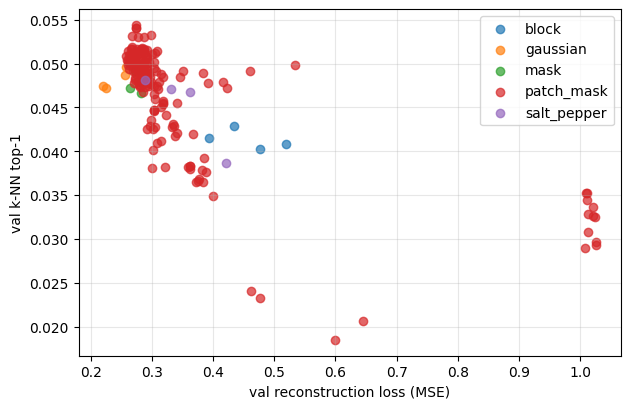

Spearman correlation: -0.725


In [12]:
trials = pd.DataFrame(results).drop_duplicates(subset="run")  # each run once
trials.to_csv(f"{OUT}/dae_grid_results.csv", index=False)
fig, ax = plt.subplots(figsize=(7, 4.5))
for noise, group in trials.groupby("noise_type"):
    ax.scatter(group["val_loss"], group["val_knn"], label=noise, alpha=0.7)
ax.set_xlabel("val reconstruction loss (MSE)")
ax.set_ylabel("val k-NN top-1")
ax.legend()
ax.grid(alpha=0.3)
plt.show()
print("Spearman correlation:", round(trials["val_loss"].corr(trials["val_knn"], method="spearman"), 3))